In [39]:
import numpy as np
import astropy.units as u
from astropy.io import fits 
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from astropy.table import Table
import glob
from pathlib import Path
from comb_grat import combine_filters, load_1d_spec
from scipy.ndimage import median_filter
from scipy.stats import median_abs_deviation

plt.rcParams.update({
#"text.usetex": True,
'axes.labelsize' : 16,
'xtick.labelsize' : 14,
'ytick.labelsize' : 14,
'xtick.direction' : "in",
'ytick.direction' : "in",
'xtick.top' : True,
'ytick.right' : True,
"xtick.minor.visible" : False,
"ytick.minor.visible" : False,
"font.family" : "serif"})

In [30]:
oceans_targets_cat = Table.read("/Users/madisynbrooks/Documents/OCEANS/Data/OCEANS_target_catalog (1).fits")
data_direc = Path("/Users/madisynbrooks/Documents/OCEANS/Data/v0.3/x1d")
save_direc = Path("/Users/madisynbrooks/Documents/OCEANS/Data/v0.3/combined_x1d")

median_diffs = []

## loop through 6 OCEANS pointings 
for pointing_num in range(1, 7):
    col_name = f"in_{pointing_num}"

    print(f"Running comb_spec for P{pointing_num}...")

    for source in oceans_targets_cat:
        # only grab sources in the current pointing
        if source[col_name] == 1:
            ## get source id 
            source_id = source["OCEANS_APT_ID"].zfill(9)
    
            # Build search paths using pathlib
            p_dir = f"P{pointing_num}"
            file_235 = glob.glob(str(data_direc / p_dir / f"*_g235h_s{source_id}*.fits"))
            file_395 = glob.glob(str(data_direc / p_dir / f"*_g395h_s{source_id}*.fits"))

            # Ensure both filter files were found
            if not file_235 or not file_395:
                continue
            comb_fits, median_diff = combine_filters(file_235[0], file_395[0], source_id, plot_spec=False)

            ## save median differences 
            median_diffs.append(median_diff)

            # Define output destination and write
            out_dir = save_direc / p_dir
            out_dir.mkdir(parents=True, exist_ok=True)  # Create P1..P6 subfolders if missing
            
            outname = out_dir / f"s{source_id}_x1d_combgrat.fits"
            comb_fits.writeto(outname, overwrite=True)

    print("...comb_spec complete.")

Running comb_spec for P1...
...comb_spec complete.
Running comb_spec for P2...
...comb_spec complete.
Running comb_spec for P3...
...comb_spec complete.
Running comb_spec for P4...


/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)
/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)
/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)
/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)
/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)


...comb_spec complete.
Running comb_spec for P5...


/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)


...comb_spec complete.
Running comb_spec for P6...


/Users/madisynbrooks/Documents/OCEANS/Optimal Extraction/comb_grat.py:225: RuntimeWarning: All-NaN slice encountered
  median_395 = np.nanmedian(flux_395_overlap)


...comb_spec complete.


Text(0, 0.5, 'Number')

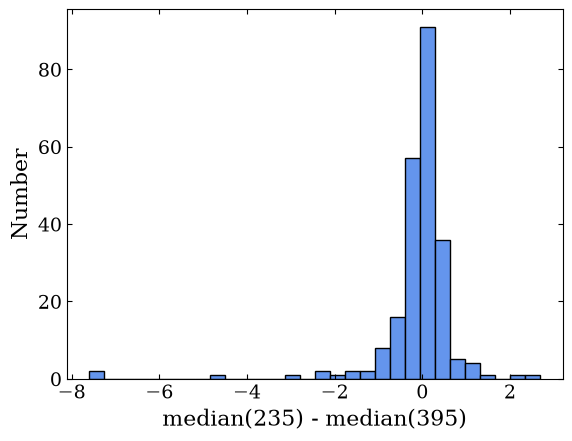

In [12]:
plt.hist(np.array(median_diffs) * 1e30, bins = 30,
        color = "cornflowerblue", edgecolor = "black")
plt.xlabel("median(235) - median(395)")
plt.ylabel("Number")

/Users/madisynbrooks/Documents/OCEANS/Data/v0.3/combined_x1d/P1/s000148165_x1d_combgrat.fits


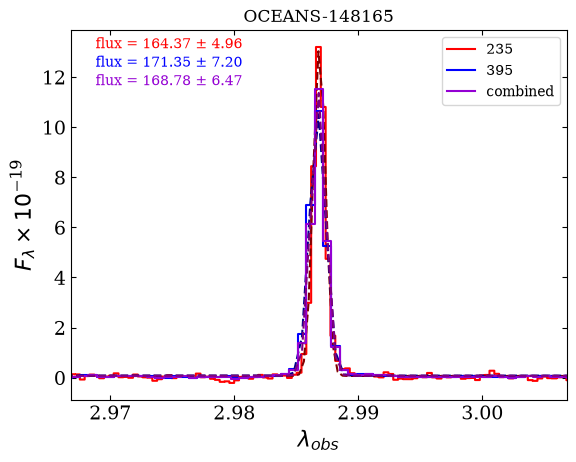

/Users/madisynbrooks/Documents/OCEANS/Data/v0.3/combined_x1d/P1/s000025277_x1d_combgrat.fits


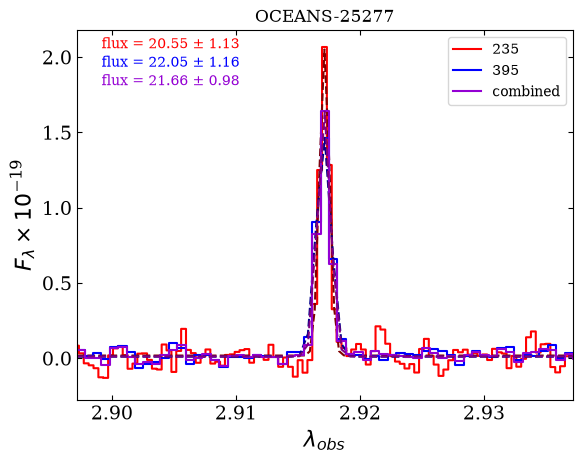

/Users/madisynbrooks/Documents/OCEANS/Data/v0.3/combined_x1d/P3/s000019175_x1d_combgrat.fits


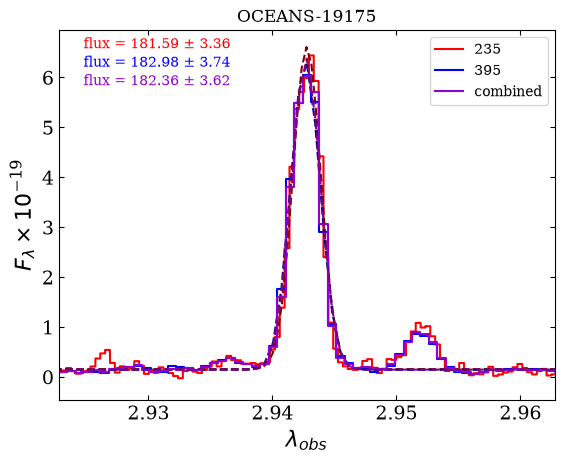

In [16]:
from astropy.modeling import models, fitting
## opening up source 0148165, 25277, 19175, 148738 to see if flux is conserved post combined grating
ids_find = [148165, 25277, 19175]

for source in ids_find:
    source_id = str(source).zfill(9)

    file_235 = glob.glob(str(data_direc / "*" / f"*_g235h_s{source_id}*.fits"))
    file_395 = glob.glob(str(data_direc / "*" / f"*_g395h_s{source_id}*.fits"))
    file_comb_spec = glob.glob(str(save_direc / "*" / f"s{source_id}*.fits"))
    
    wv_235, fnu_235, fnu_err_235, flam_235, flam_err_235 = load_1d_spec(file_235[0])
    wv_395, fnu_395, fnu_err_395, flam_395, flam_err_395 = load_1d_spec(file_395[0])
    wv_comb, fnu_comb, fnu_err_comb, fnu_lam_comb, fnu_err_comb = load_1d_spec(file_comb_spec[0])
    print(file_comb_spec[0])

    ## removing units 
    wv_235, fnu_235, fnu_err_235, flam_235, flam_err_235 = wv_235.value, fnu_235.value, fnu_err_235.value, flam_235.value, flam_err_235.value
    wv_395, fnu_395, fnu_err_395, flam_395, flam_err_395 = wv_395.value, fnu_395.value, fnu_err_395.value, flam_395.value, flam_err_395.value
    wv_comb, fnu_comb, fnu_err_comb, flam_comb, fnu_err_comb = wv_comb.value, fnu_comb.value, fnu_err_comb.value, fnu_lam_comb.value, fnu_err_comb.value


    ## find overlap between 235 and 395 wavelengths
    min_wv_235, max_wv_235 = np.nanmin(wv_235), np.nanmax(wv_235)
    min_wv_395, max_wv_395 = np.nanmin(wv_395), np.nanmax(wv_395)

    ## minumum and maxium wavelenghts of the overlapping region
    overlapping_min = max(min_wv_235, min_wv_395)
    overlapping_max = min(max_wv_235, max_wv_395)

    mask_235 = (wv_235 >= overlapping_min) & (wv_235 <= overlapping_max)
    mask_395 = (wv_395 >= overlapping_min) & (wv_395 <= overlapping_max)
    mask_comb = (wv_comb >= overlapping_min) & (wv_comb <= overlapping_max)

    ## lets find the peak of the data for each file, and fit a single Gaussian to that emission line 
    peak_index = np.nanargmax(flam_comb[mask_comb])
    wv_max = wv_comb[mask_comb][peak_index]

    fitter = fitting.LevMarLSQFitter(calc_uncertainties=True) ## least-squares fitting is the most common method 

    g_init_narrow = models.Gaussian1D(amplitude = 5, mean = wv_max, stddev = .01)
    g_init_constant = models.Const1D(0) ## we add a constant model because of the continuum light from the galaxy, its sort of like a "base line"
    g_init = g_init_narrow + g_init_constant

    fitted_model_235 = fitter(g_init, wv_235[mask_235], flam_235[mask_235] * 1e19, filter_non_finite=True)
    fitted_model_395 = fitter(g_init, wv_395[mask_395], flam_395[mask_395] * 1e19, filter_non_finite=True)
    fitted_model_comb = fitter(g_init, wv_comb[mask_comb], flam_comb[mask_comb] * 1e19, filter_non_finite=True)
    #print(wv_235[mask_235], flam_235[mask_235] * 1e19)

    plt.plot(wv_235[mask_235], flam_235[mask_235] * 1e19, drawstyle = "steps-mid", color = "red", label = "235")
    plt.plot(wv_235[mask_235], fitted_model_235(wv_235[mask_235]), linestyle = "--", color = "maroon")
    amp = fitted_model_235.amplitude_0
    stddev = fitted_model_235.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)
    # --- flux error propagation ---
    amp_err = fitted_model_235.stds.stds[fitted_model_235.param_names.index('amplitude_0')]
    stddev_err = fitted_model_235.stds.stds[fitted_model_235.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.95, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "red",
             transform=ax.transAxes)

    
    plt.plot(wv_395[mask_395], flam_395[mask_395] * 1e19, drawstyle = "steps-mid", color = "blue", label = "395")
    plt.plot(wv_395[mask_395], fitted_model_395(wv_395[mask_395]), linestyle = "--", color = "darkblue")
    amp = fitted_model_395.amplitude_0
    stddev = fitted_model_395.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)

    # --- flux error propagation ---
    amp_err = fitted_model_395.stds.stds[fitted_model_395.param_names.index('amplitude_0')]
    stddev_err = fitted_model_395.stds.stds[fitted_model_395.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.9, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "blue",
             transform=ax.transAxes)
    
    
    plt.plot(wv_comb[mask_comb], flam_comb[mask_comb] * 1e19, drawstyle = "steps-mid", color = "darkviolet", label = "combined")
    plt.plot(wv_comb[mask_comb], fitted_model_comb(wv_comb[mask_comb]), linestyle = "--", color = "purple")
    amp = fitted_model_comb.amplitude_0
    stddev = fitted_model_comb.stddev_0 * u.micron
    flux = np.sqrt(2 * np.pi) * amp * ((stddev.to(u.angstrom)).value)

    # --- flux error propagation ---
    amp_err = fitted_model_comb.stds.stds[fitted_model_comb.param_names.index('amplitude_0')]
    stddev_err = fitted_model_comb.stds.stds[fitted_model_comb.param_names.index('stddev_0')] * u.micron
    stddev_err_ang = stddev_err.to(u.angstrom).value
    stddev_ang = stddev.to(u.angstrom).value
    flux_err = flux * np.sqrt((amp_err / amp)**2 + (stddev_err_ang / stddev_ang)**2)

    ax = plt.gca()
    plt.text(x = 0.05, y = 0.85, s = rf"flux = {flux:.2f} $\pm$ {flux_err:.2f}", color =  "darkviolet",
             transform=ax.transAxes)

    plt.xlim(wv_max - .02, wv_max + .02)
    plt.ylabel(r"$F_{\lambda} \times 10^{-19}$")
    plt.xlabel(r"$\lambda_{obs}$")
    plt.title(f"OCEANS-{source}")
    
    plt.legend()
    plt.show()

In [35]:
oceans_targets_cat[oceans_targets_cat['ZSPEC'] > 1]

OCEANS_APT_ID,RA,DEC,ZPHOT,ZSPEC,THETA_SKY_JWST,THETA_SKY_HST,NMASKS,in_1,in_2,in_3,in_4,in_5,in_6
bytes6,float64,float64,float64,float64,float32,float64,int64,int16,int16,int16,int16,int16,int16
011576,215.03316952349599,52.877616505928586,1.450000000000001,1.35962,34.92,49.80000000000001,1,0,0,0,0,1,0
169018,215.03539123102095,52.89067246163631,8.680000000000007,8.678999900817871,38.97,41.900000000000006,1,0,0,0,0,1,0
013636,214.85764074327753,52.76632477754767,3.0699999999999945,3.01,36.11,--,1,1,0,0,0,0,0
014301,215.0146061056383,52.88140604026849,1.5400000000000011,1.3569,11.459999,10.099999999999994,1,0,0,0,0,1,0
015080,215.05635026139922,52.91551132976078,3.3999999999999924,3.453900098800659,7.8199997,54.69999999999999,1,0,0,0,0,1,0
015698,214.9491787863486,52.84318270292673,7.150000000000015,6.73,22.509995,33.900000000000006,1,0,0,0,0,0,1
089981,214.8195895609279,52.75271325012093,4.029999999999989,3.92,84.81,-84.1,1,1,0,0,0,0,0
090347,214.9067876610937,52.816773176684016,1.1500000000000008,2.319499969482422,-63.740005,37.3,1,0,0,0,0,0,1
090849,214.99598368475245,52.88313043788068,0.9700000000000006,3.217900037765503,54.979996,-13.5,1,0,0,0,0,1,0


In [58]:
## compare nmad to pixel level uncertainties for each spectra 
## loop through 6 OCEANS pointings 

nmads_235 = []
median_err_235 = []

for pointing_num in range(1, 7):
    col_name = f"in_{pointing_num}"
    print(f"P{pointing_num}...")

    for source in oceans_targets_cat:
        # only grab sources in the current pointing
        if source[col_name] == 1:
            ## get source id 
            source_id = source["OCEANS_APT_ID"].zfill(9)
            z = source['ZSPEC']
            # Build search paths using pathlib
            p_dir = f"P{pointing_num}"
            file_235 = glob.glob(str(data_direc / p_dir / f"*_g235h_s{source_id}*.fits"))
            file_395 = glob.glob(str(data_direc / p_dir / f"*_g395h_s{source_id}*.fits"))

            # Ensure both filter files were found
            if not file_235 or not file_395:
                continue
            else:
                ## open data files 
                wv_235, fnu_235, fnu_err_235, flam_235, flam_err_235 = load_1d_spec(file_235[0])
                wv_395, fnu_395, fnu_err_395, flam_395, flam_err_395 = load_1d_spec(file_395[0])

            #plt.plot(wv_235, flam_235, drawstyle = "steps-mid")
            filtered_spec = median_filter(flam_235, size = 121)
            #plt.plot(wv_235, filtered_spec)
            #plt.show()

            spec_235_cont_removed = flam_235.value - filtered_spec
            ## compute normalized absolute deviation of spectra 
            ## might need to do this for just a continuum region and mask out emission lines
            spec_nmad = 1.4826 * median_abs_deviation(spec_235_cont_removed, nan_policy = "omit")
            spec_std = np.nanmedian(flam_err_235.value)

            ## append to arrays for comparision
            nmads_235.append(spec_nmad)
            median_err_235.append(spec_std)


            

            

P1...
P2...
P3...
P4...
P5...
P6...


In [59]:
nmads_235

[np.float64(7.410383396319739e-21),
 np.float64(8.937397478789264e-21),
 np.float64(8.509334459123012e-21),
 np.float64(9.722582975180006e-21),
 np.float64(9.274396262887133e-21),
 np.float64(1.0028219522807238e-20),
 np.float64(8.775722100489729e-21),
 np.float64(8.75058084278011e-21),
 np.float64(8.403836737206179e-21),
 np.float64(8.02522383814175e-21),
 np.float64(9.306783332813589e-21),
 np.float64(7.973889045158725e-21),
 np.float64(1.3840575076050926e-20),
 np.float64(1.1924072247544296e-20),
 np.float64(9.356048561724906e-21),
 np.float64(8.063855036136033e-21),
 np.float64(8.975767852830266e-21),
 np.float64(9.271317047895504e-21),
 np.float64(1.3861635678322094e-20),
 np.float64(8.304777903304786e-21),
 np.float64(8.427163608118034e-21),
 np.float64(9.279890546111684e-21),
 np.float64(1.0225847082822774e-20),
 np.float64(8.318792563700187e-21),
 np.float64(1.5336411058517578e-20),
 np.float64(7.796006403001924e-21),
 np.float64(7.749575539399435e-21),
 np.float64(8.3983087457

Text(0, 0.5, 'Median Error')

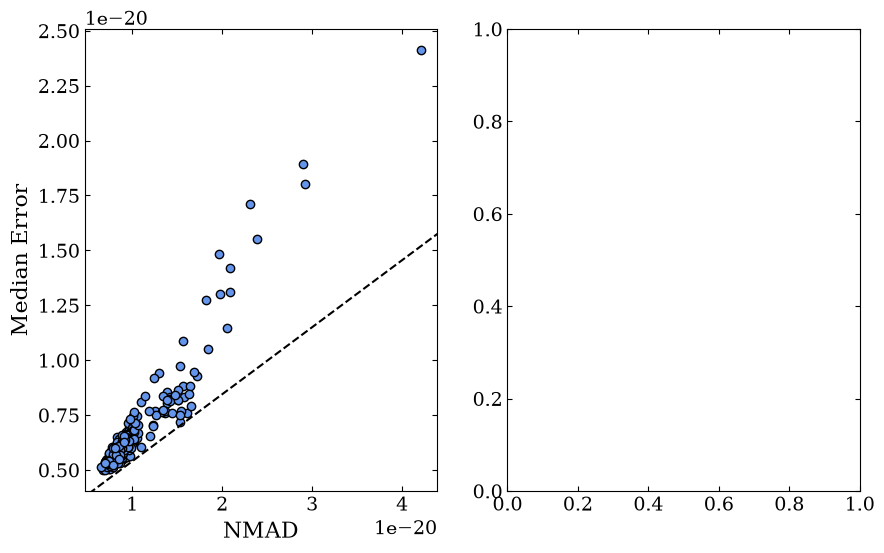

In [60]:
## looking at the difference in errors
fig, axs = plt.subplots(1,2, figsize = [10,6])

axs[0].plot(nmads_235, median_err_235,
         marker = "o",
         linestyle = "None",
         color = "cornflowerblue",
         markeredgecolor = "black"
         )
axs[0].plot([0, 1], [0, 1], transform=ax.transAxes, color='black', linestyle='--')
axs[0].set_xlabel("NMAD")
axs[0].set_ylabel("Median Error")